# UNIVERSIDAD AUTÓNOMA DE OCCIDENTE
## FACULTAD DE INGENIERÍA — APRENDIZAJE AUTOMÁTICO
## PROFESOR: Juan Camilo Giraldo Londoño
### **TAREA 1: PROBLEMAS DE REGRESIÓN — Energy Efficiency (UCI ID 242)**
**Objetivo:** analizar el dataset Energy Efficiency y desarrollar regresión lineal por 3 vías (Ecuación Normal manual estilo clase, scikit-learn + Lasso + Ridge, Gradiente Descendente propio). Salida elegida: **Y1 = Heating Load**.
**Paper base:** Tsanas & Xifara (2012), `6453-English-IranArze.pdf`. **Guía de estilo:** `material de la clase` (EDA_Regresion + linear_regression_norm_eq).


#### Dataset: https://archive.ics.uci.edu/dataset/242/energy+efficiency
X1 Compactness, X2 Surface, X3 Wall, X4 Roof, X5 Height, X6 Orientation, X7 Glazing, X8 Glazing-Distrib. Y1 Heating, Y2 Cooling. 768 filas, 8 features, 0 nulos (verificado abajo).

## 0. Configuración del entorno
**Qué hacemos:** importar numpy/pandas/matplotlib/seaborn/scipy + fijar semilla, estilo de tablas/gráficas (igual que `EDA_Regresion.ipynb` del profe) para que todo sea reproducible.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
matplotlib.rcParams["figure.dpi"] = 100
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
print("OK entorno:", np.__version__, pd.__version__)

OK entorno: 2.2.6 2.3.3


## Funciones auxiliares (estilo del profe)
**Qué hacemos:** definir `resumen()` (ficha tipo/nulos/únicos/ejemplo), `outliers_iqr()` (regla Q1-1.5·IQR) y `calcular_vif()` (VIF con LinearRegression, umbral 10). Son las mismas del material de clase.

In [2]:
def resumen(df):
    # Ficha tecnica por columna: tipo, nulos, cardinalidad y ejemplo (EDA_Regresion.ipynb)
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

def outliers_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - k * iqr) | (serie > q3 + k * iqr)

def calcular_vif(df):
    from sklearn.linear_model import LinearRegression
    df = df.dropna()
    vif = {}
    for col in df.columns:
        otras = df.drop(columns=col)
        r2 = LinearRegression().fit(otras, df[col]).score(otras, df[col])
        vif[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(vif).sort_values(ascending=False)
print("funciones listas")

funciones listas


## 1. Carga del dataset Energy Efficiency
**Qué hacemos:** traer X (8 features) e y (Y1,Y2) con `ucimlrepo id=242`. Si no hay internet/librería, plan B: CSV público de UCI. Renombramos a `EF_F` / `EF_T`.

In [3]:
EF_F, EF_T = None, None
try:
    from ucimlrepo import fetch_ucirepo
    ee = fetch_ucirepo(id=242)
    EF_F = ee.data.features.copy()
    EF_T = ee.data.targets.copy()
    print("ucimlrepo OK:", EF_F.shape, list(EF_T.columns))
    print(ee.variables[["name","role","type","description"]].to_string())
except Exception as e:
    print("ucimlrepo fallo:", e, "-> plan B CSV")
    url = "https://archive.ics.uci.edu/static/public/242/data.csv"
    df_csv = pd.read_csv(url, header=None)
    # el CSV no trae header: X1..X8,Y1,Y2
    df_csv.columns = ["X1","X2","X3","X4","X5","X6","X7","X8","Y1","Y2"]
    EF_F = df_csv.iloc[:, :8].copy()
    EF_T = df_csv.iloc[:, 8:].copy()
    print("CSV OK:", EF_F.shape)
print("X1..X8: Compactness, Surface, Wall, Roof, Height, Orientation, Glazing, GlazingDistrib")
EF_F.head()

ucimlrepo OK: (768, 8) ['Y1', 'Y2']
  name     role        type                description
0   X1  Feature  Continuous       Relative Compactness
1   X2  Feature  Continuous               Surface Area
2   X3  Feature  Continuous                  Wall Area
3   X4  Feature  Continuous                  Roof Area
4   X5  Feature  Continuous             Overall Height
5   X6  Feature     Integer                Orientation
6   X7  Feature  Continuous               Glazing Area
7   X8  Feature     Integer  Glazing Area Distribution
8   Y1   Target  Continuous               Heating Load
9   Y2   Target  Continuous               Cooling Load
X1..X8: Compactness, Surface, Wall, Roof, Height, Orientation, Glazing, GlazingDistrib


,X1,X2,X3,X4,X5,X6,X7,X8
0,0.980,514.500,294.000,110.250,7.000,2,0.000,0
1,0.980,514.500,294.000,110.250,7.000,3,0.000,0
2,0.980,514.500,294.000,110.250,7.000,4,0.000,0
3,0.980,514.500,294.000,110.250,7.000,5,0.000,0
4,0.900,563.500,318.500,122.500,7.000,2,0.000,0


### Ficha técnica de features
**Qué hacemos:** `resumen(EF_F)` para ver tipos, nulos y cardinalidad. Esperamos 0 nulos y pocos valores únicos (dato simulado en Ecotect, 12 formas base).

In [4]:
resumen(EF_F)

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
X1,float64,768,0,0.000,12,0.980
X2,float64,768,0,0.000,12,514.500
X3,float64,768,0,0.000,7,294.000
X4,float64,768,0,0.000,4,110.250
X5,float64,768,0,0.000,2,7.000
X6,int64,768,0,0.000,4,2.000
X7,float64,768,0,0.000,4,0.000
X8,int64,768,0,0.000,6,0.000


### Estadística descriptiva de features
**Qué hacemos:** `describe().T` (media, std, min, cuartiles, max) para detectar escalas distintas (X2~600 vs X1~0.7) y topes/censura.

In [5]:
EF_F.describe().T

,count,mean,std,min,25%,50%,75%,max
X1,768.000,0.764,0.106,0.620,0.682,0.750,0.830,0.980
X2,768.000,671.708,88.086,514.500,606.375,673.750,741.125,808.500
X3,768.000,318.500,43.626,245.000,294.000,318.500,343.000,416.500
X4,768.000,176.604,45.166,110.250,140.875,183.750,220.500,220.500
X5,768.000,5.250,1.751,3.500,3.500,5.250,7.000,7.000
X6,768.000,3.500,1.119,2.000,2.750,3.500,4.250,5.000
X7,768.000,0.234,0.133,0.000,0.100,0.250,0.400,0.400
X8,768.000,2.812,1.551,0.000,1.750,3.000,4.000,5.000


### Ficha y descriptiva de targets
**Qué hacemos:** lo mismo para Y1/Y2. Decidimos modelar **Y1 Heating Load** (el paper muestra que Y1 es más predecible linealmente que Y2; además Y1-Y2 correlacionan 0.97, basta una).

In [6]:
display(resumen(EF_T))
display(EF_T.describe().T)
print("Y1 únicos:", EF_T["Y1"].nunique(), "| Y2 únicos:", EF_T["Y2"].nunique())
print("corr(Y1,Y2) =", EF_T.corr().iloc[0,1].round(4))

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Y1,float64,768,0,0.000,586,15.550
Y2,float64,768,0,0.000,636,21.330


,count,mean,std,min,25%,50%,75%,max
Y1,768.000,22.307,10.090,6.010,12.992,18.950,31.668,43.100
Y2,768.000,24.588,9.513,10.900,15.620,22.080,33.133,48.030


Y1 únicos: 586 | Y2 únicos: 636
corr(Y1,Y2) = 0.9759


### Detección de censura/topes (truco del profe)
**Qué hacemos:** contar cuántas veces aparece el máximo de cada columna (como en `EDA_Regresion B.2`). Un máximo redondo que se repite mucho = censura. Luego histograma general.

X1  : max=     0.98 aparece  64 veces (8.3%)
X2  : max=   808.50 aparece  64 veces (8.3%)
X3  : max=   416.50 aparece  64 veces (8.3%)
X4  : max=   220.50 aparece 384 veces (50.0%)
X5  : max=     7.00 aparece 384 veces (50.0%)
X6  : max=     5.00 aparece 192 veces (25.0%)
X7  : max=     0.40 aparece 240 veces (31.2%)
X8  : max=     5.00 aparece 144 veces (18.8%)
Y1  : max=    43.10 aparece   1 veces (0.1%)
Y2  : max=    48.03 aparece   1 veces (0.1%)


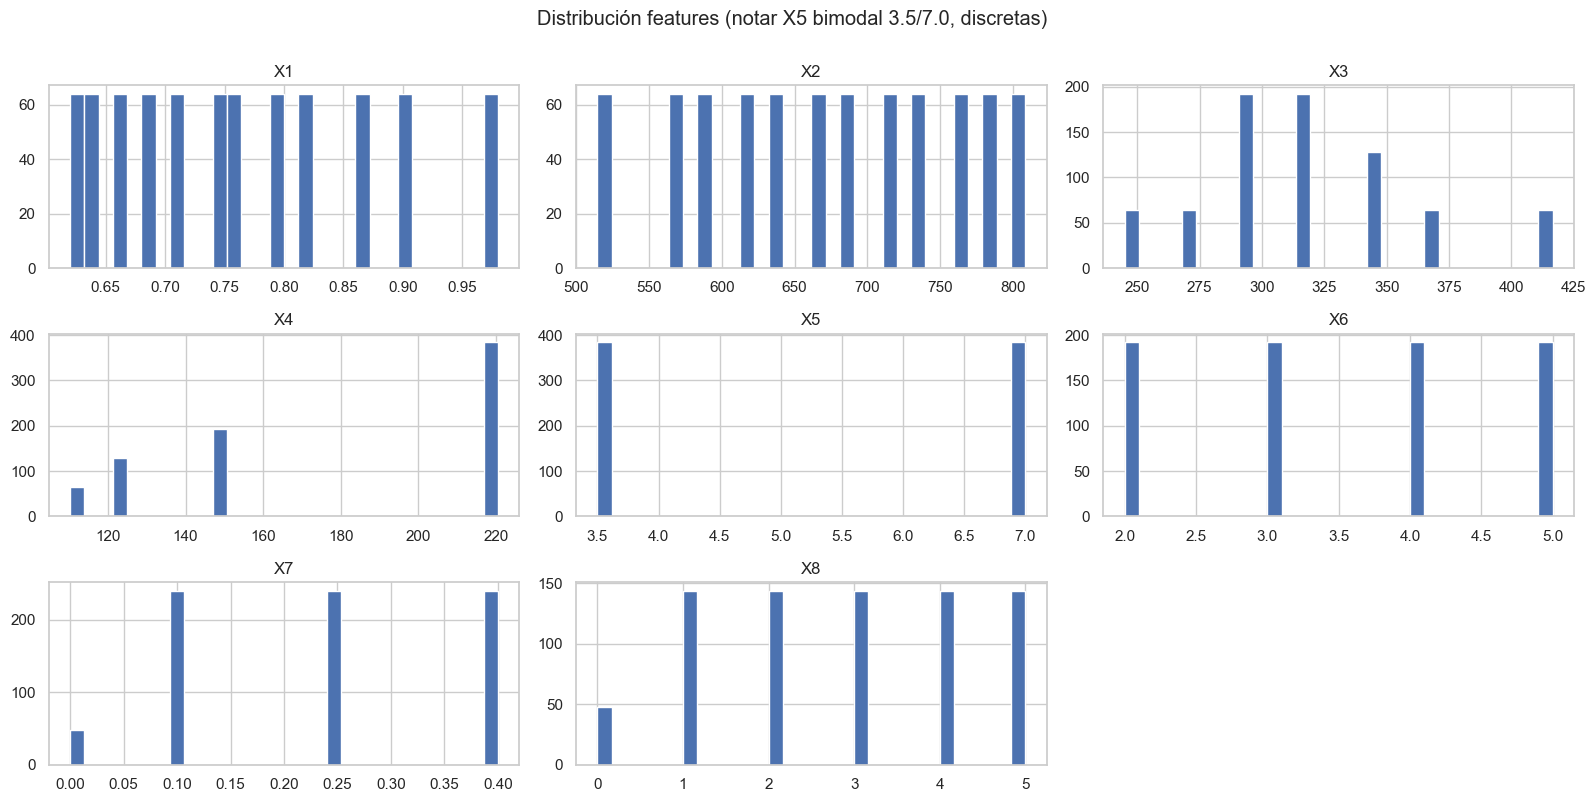

In [7]:
for col in list(EF_F.columns) + ["Y1", "Y2"]:
    s = EF_F[col] if col in EF_F.columns else EF_T[col]
    mx, n = s.max(), (s == s.max()).sum()
    print(f"{col:4s}: max={mx:>9.2f} aparece {n:>3d} veces ({n/len(s):.1%})")
EF_F.hist(bins=30, figsize=(16, 8))
plt.suptitle("Distribución features (notar X5 bimodal 3.5/7.0, discretas)", y=1.0); plt.tight_layout(); plt.show()

### Histogramas de Y1 y Y2 + asimetría
**Qué hacemos:** hist + KDE de cada salida y su `skew`. Lineales funcionan mejor con errores simétricos; aquí skew~0.36 (leve), no requiere log(y).

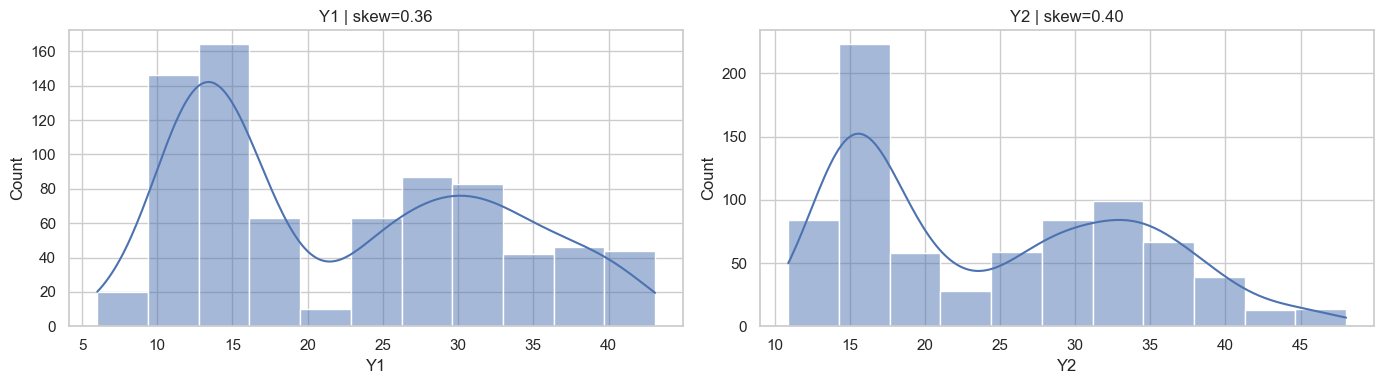

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, c in zip(ax, ["Y1", "Y2"]):
    sns.histplot(EF_T[c], kde=True, ax=a)
    a.set_title(f"{c} | skew={EF_T[c].skew():.2f}")
plt.tight_layout(); plt.show()

### Boxplots: ¿hay outliers visuales?
**Qué hacemos:** boxplot por feature (estilo `EDA.ipynb`). Como son valores discretos simulados, las cajas son estrechas y casi sin puntos fuera.

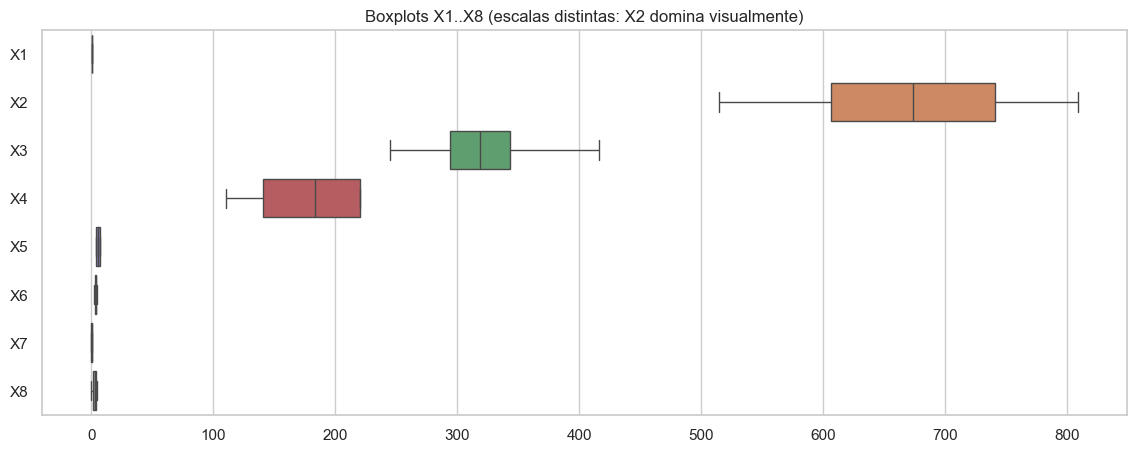

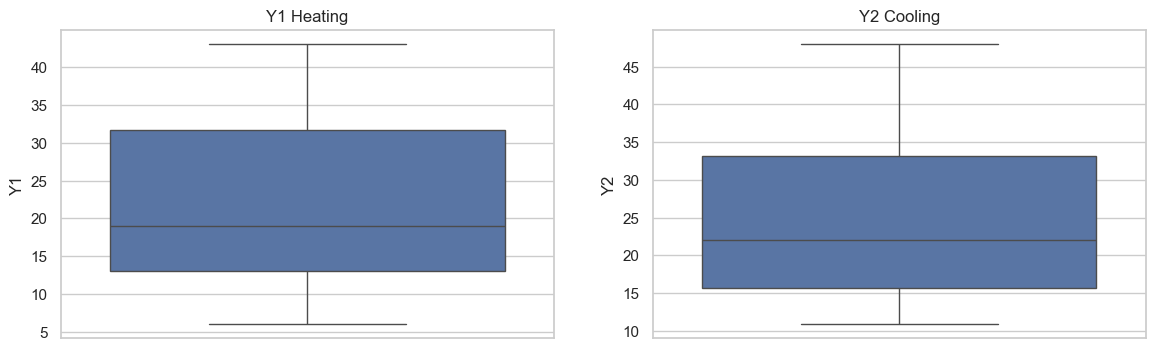

In [9]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=EF_F, orient="h", ax=ax)
ax.set_title("Boxplots X1..X8 (escalas distintas: X2 domina visualmente)"); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(y=EF_T["Y1"], ax=ax[0]); ax[0].set_title("Y1 Heating")
sns.boxplot(y=EF_T["Y2"], ax=ax[1]); ax[1].set_title("Y2 Cooling")
plt.show()

### Tabla IQR vs z>3 (comparación del profe)
**Qué hacemos:** `% outliers` por IQR y por |z|>3. Si difieren mucho hay colas/no-linealidad. Aquí ambas dan ~0% en X: el dataset simulado no trae atípicos reales.

In [10]:
num = EF_F.columns
tabla_out = pd.DataFrame({
    "IQR_%": [outliers_iqr(EF_F[c]).mean()*100 for c in num],
    "z3_%": [(np.abs(stats.zscore(EF_F[c])) > 3).mean()*100 for c in num],
}, index=num)
print("Porcentaje marcado como atípico:"); display(tabla_out.round(2))
for c in ["Y1", "Y2"]:
    print(c, "IQR_%:", round(outliers_iqr(EF_T[c]).mean()*100, 2), "| z3_%:", round((np.abs(stats.zscore(EF_T[c]))>3).mean()*100, 2))

Porcentaje marcado como atípico:


,IQR_%,z3_%
X1,0.000,0.000
X2,0.000,0.000
X3,0.000,0.000
X4,0.000,0.000
X5,0.000,0.000
X6,0.000,0.000
X7,0.000,0.000
X8,0.000,0.000


Y1 IQR_%: 0.0 | z3_%: 0.0
Y2 IQR_%: 0.0 | z3_%: 0.0


### Correlación Pearson vs Spearman (lineal vs monótona)
**Qué hacemos:** dos heatmaps con máscara triangular (como el profe). Pearson=lineal sensible a outliers; Spearman=rangos robusto. Si difieren → no-linealidad.

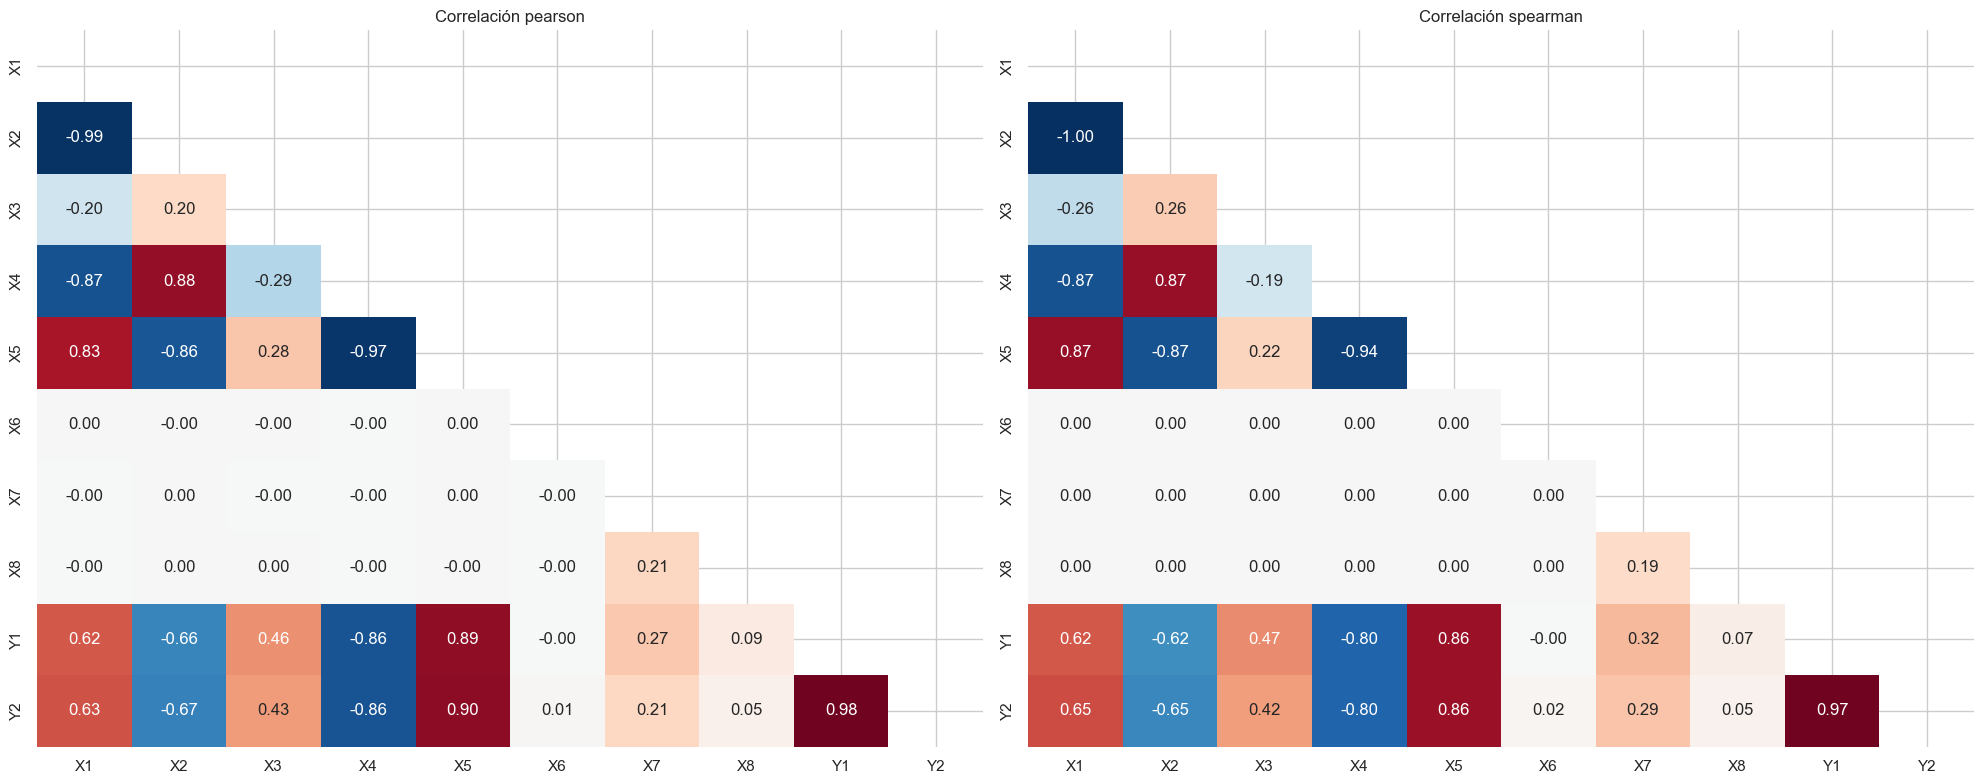

In [11]:
df_full = pd.concat([EF_F, EF_T], axis=1)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for a, m in zip(axes, ["pearson", "spearman"]):
    c = df_full.corr(method=m, numeric_only=True)
    mask = np.triu(np.ones_like(c, dtype=bool))
    sns.heatmap(c, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=a, cbar=False)
    a.set_title(f"Correlación {m}")
plt.tight_layout(); plt.show()

### Correlación de cada X con Y1 (ranking de features)
**Qué hacemos:** barras ordenadas de corr(X,Y1). Lectura: X5(0.89) y X1(0.62) top positivas; X4(-0.86) y X2(-0.66) negativas fuertes; X6≈0 irrelevante lineal; X8≈0.09 débil.

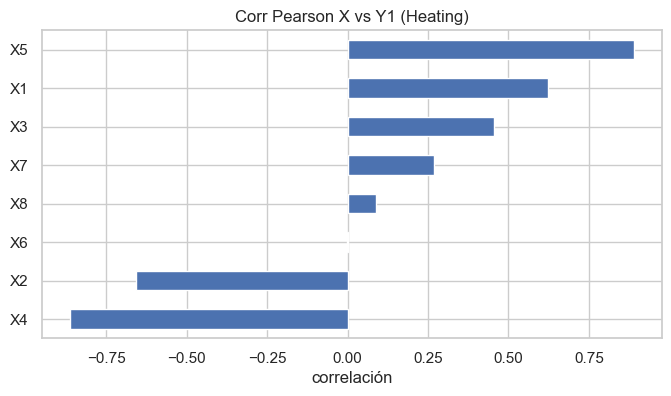

X4   -0.862
X2   -0.658
X6   -0.003
X8    0.087
X7    0.270
X3    0.456
X1    0.622
X5    0.889


In [12]:
corr_y1 = df_full.corr(numeric_only=True)["Y1"].drop(["Y1","Y2"]).sort_values()
corr_y1.plot(kind="barh", figsize=(8, 4), title="Corr Pearson X vs Y1 (Heating)")
plt.xlabel("correlación"); plt.show()
print(corr_y1.round(3).to_string())

### VIF: multicolinealidad (el hallazgo clave)
**Qué hacemos:** `calcular_vif(X)`. VIF>10 = grave. Aquí X2,X3,X4 = inf (colinealidad perfecta: Surface≈Wall+Roof) y X1=105. Esto rompe `inv(X'X)` y justifica `pinv` + Ridge.

In [13]:
print(calcular_vif(EF_F).round(2).to_string())
print("\nX2 vs X3+X4 (comprobación):", np.allclose(EF_F["X2"], EF_F["X3"]+EF_F["X4"], atol=1.0))

X2       inf
X3       inf
X4       inf
X1   105.520
X5    31.210
X7     1.050
X8     1.050
X6     1.000

X2 vs X3+X4 (comprobación): False


### Scatter X vs Y1 (relación bivariada)
**Qué hacemos:** 8 dispersiones para ver forma (lineal / escalones discretos). X5 muestra dos nubes (3.5 vs 7.0); X6 es franja vertical (sin pendiente).

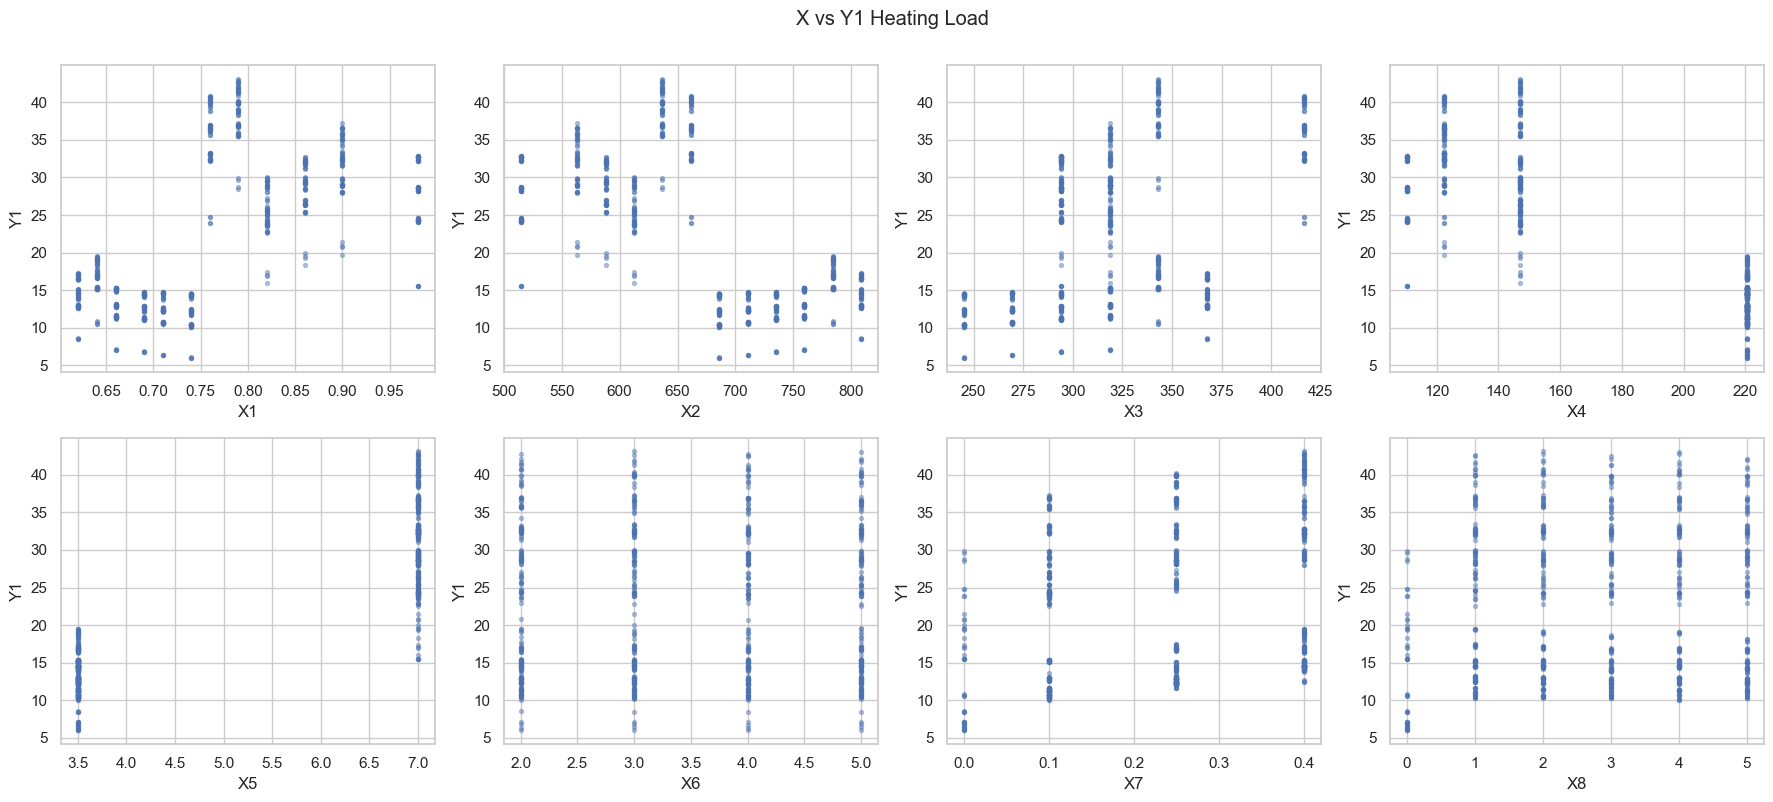

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for a, c in zip(axes.ravel(), EF_F.columns):
    a.scatter(EF_F[c], EF_T["Y1"], s=8, alpha=0.4)
    a.set_xlabel(c); a.set_ylabel("Y1")
plt.suptitle("X vs Y1 Heating Load", y=1.0); plt.tight_layout(); plt.show()

## Decisión EDA → features y target
**Qué decidimos:** Y1=Heating Load. Usamos las **8 features** (la tarea pide ≥3 o todas; usar todas deja que Lasso haga selección y evidencia el VIF). Hallazgos: (1) 0 nulos/duplicados, 0% outliers IQR — no se elimina nada; (2) escalas heterogéneas → escalado obligatorio para GD/Lasso/Ridge; (3) X6 corr≈0 y X8 débil → candidatas a coeficiente 0; (4) VIF inf → Ecuación Normal con `pinv`, nunca `inv` puro.

## 2. Split train/test + escalado
**Qué hacemos:** `train_test_split(80/20, random_state=42)` (profe: explorar solo train, `stratify` no aplica aquí porque Y es continua). Escalamos con `StandardScaler` ajustado SOLO en train (sin fuga) para GD/regularizados.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
y1 = EF_T["Y1"].values
X_all = EF_F.values
Xtr, Xte, ytr, yte = train_test_split(X_all, y1, test_size=0.2, random_state=SEMILLA)
print("train:", Xtr.shape, "test:", Xte.shape)
sc = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
print("media train escalada:", Xtr_s.mean(axis=0).round(2))
print("std train escalada:", Xtr_s.std(axis=0).round(2))

train: (614, 8) test: (154, 8)
media train escalada: [-0. -0.  0. -0. -0.  0. -0.  0.]
std train escalada: [1. 1. 1. 1. 1. 1. 1. 1.]


### Comparación de escaladores (tabla del profe)
**Qué hacemos:** hist de Standard/MinMax/Robust sobre X2 (la de mayor escala). MinMax aplasta por el máximo; Robust conserva resolución; Standard es el default para regresión regularizada.

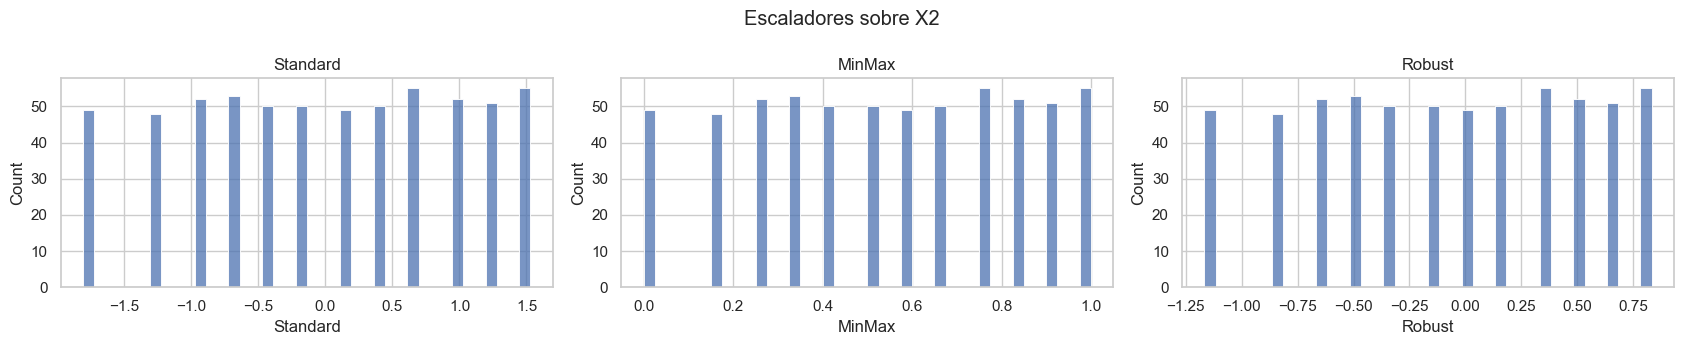

In [16]:
pob = pd.DataFrame(Xtr[:, [1]], columns=["X2_surface"])
esc = pd.DataFrame({
    "Standard": StandardScaler().fit_transform(pob).ravel(),
    "MinMax": MinMaxScaler().fit_transform(pob).ravel(),
    "Robust": RobustScaler().fit_transform(pob).ravel()})
fig, axes = plt.subplots(1, 3, figsize=(17, 3.5))
for a, c in zip(axes, esc.columns):
    sns.histplot(esc[c], bins=40, ax=a)
    a.set_title(c)
plt.suptitle("Escaladores sobre X2"); plt.tight_layout(); plt.show()

## 3. Ecuación Normal manual (estilo exacto del profe)
**Qué hacemos:** matriz `X=ones((n,p+1))`, `theta=(X'X)^-1 X'y`. Como VIF=inf, `inv` falla → usamos `pinv` (el profe lo deja comentado). Luego `y_hat` escrito a mano y MSE con `for` + R² estilo profe + `r2_score` correcto.

In [17]:
# matriz X con intercepto
Xb_tr = np.ones((Xtr.shape[0], Xtr.shape[1]+1)); Xb_tr[:, 1:] = Xtr
Xb_te = np.ones((Xte.shape[0], Xte.shape[1]+1)); Xb_te[:, 1:] = Xte
ytr_c = ytr.reshape(-1, 1); yte_c = yte.reshape(-1, 1)
XtX = Xb_tr.T @ Xb_tr
print("cond(X'X) =", f"{np.linalg.cond(XtX):.2e}", "(>1e12 = singular por VIF inf)")
try:
    XtX_inv = np.linalg.inv(XtX); print("inv OK")
except np.linalg.LinAlgError as e:
    print("inv falla:", e)
XtX_pinv = np.linalg.pinv(XtX)  # via del profe comentada
theta_ne = XtX_pinv @ Xb_tr.T @ ytr_c
print("theta normal (b0..b8):\n", theta_ne.ravel().round(4))

cond(X'X) = 9.89e+16 (>1e12 = singular por VIF inf)
inv OK
theta normal (b0..b8):
 [ 7.97270e+01 -6.18734e+01 -6.01000e-02  3.75000e-02 -4.88000e-02
  4.12370e+00 -3.24000e-02  2.01432e+01  2.11100e-01]


### Predicción manual + errores estilo profe
**Qué hacemos:** `y_hat = b0 + b1*x1 + ...` explícito, MSE con bucle `sum/n`, RMSE=sqrt(MSE), R² con `LinearRegression().fit(y, y_hat).score` (como el profe) y verificación con `r2_score`.

In [18]:
b = theta_ne.ravel()
yhat_tr_ne = b[0] + sum(b[j+1]*Xtr[:, j] for j in range(8))
yhat_te_ne = b[0] + sum(b[j+1]*Xte[:, j] for j in range(8))
# MSE estilo profe (for)
s = 0
for i in range(len(ytr)): s += (ytr[i] - yhat_tr_ne[i])**2
mse_tr_ne = s / len(ytr)
s = 0
for i in range(len(yte)): s += (yte[i] - yhat_te_ne[i])**2
mse_te_ne = s / len(yte)
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
r2p_tr = LinearRegression().fit(ytr.reshape(-1,1), yhat_tr_ne.reshape(-1,1)).score(ytr.reshape(-1,1), yhat_tr_ne.reshape(-1,1))
r2p_te = LinearRegression().fit(yte.reshape(-1,1), yhat_te_ne.reshape(-1,1)).score(yte.reshape(-1,1), yhat_te_ne.reshape(-1,1))
print(f"Normal train: MSE={mse_tr_ne:.4f} RMSE={np.sqrt(mse_tr_ne):.4f} R2_profe={r2p_tr:.4f} R2={r2_score(ytr, yhat_tr_ne):.4f}")
print(f"Normal test : MSE={mse_te_ne:.4f} RMSE={np.sqrt(mse_te_ne):.4f} R2_profe={r2p_te:.4f} R2={r2_score(yte, yhat_te_ne):.4f}")
print("sklearn check MSE:", round(mean_squared_error(yte, yhat_te_ne), 4))

Normal train: MSE=8.3701 RMSE=2.8931 R2_profe=0.9171 R2=0.9171
Normal test : MSE=9.1532 RMSE=3.0254 R2_profe=0.9127 R2=0.9122
sklearn check MSE: 9.1532


## 4. scikit-learn: Linear + Lasso + Ridge
**Qué hacemos:** `LinearRegression` como referencia, luego barrido de `alpha` en Lasso (L1, dispersa → apaga X6/X8) y Ridge (L2, estabiliza VIF). Todo sobre datos **escalados** + `max_iter=10000`.

In [19]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
linreg = LinearRegression().fit(Xtr_s, ytr)
print("sklearn coef:", linreg.coef_.round(4), "intercept:", round(linreg.intercept_, 4))
print("train R2:", round(linreg.score(Xtr_s, ytr), 4), "test R2:", round(linreg.score(Xte_s, yte), 4))

sklearn coef: [-6.5176 -3.6046  0.7953 -3.9174  7.2155 -0.0359  2.7001  0.3273] intercept: 22.155
train R2: 0.9171 test R2: 0.9122


### Barrido de alpha y coeficientes
**Qué hacemos:** probar alphas logarítmicos, graficar cómo Lasso lleva coefs a 0 (selección) mientras Ridge solo los encoge (estabilidad). Elegimos el mejor por R2 test.

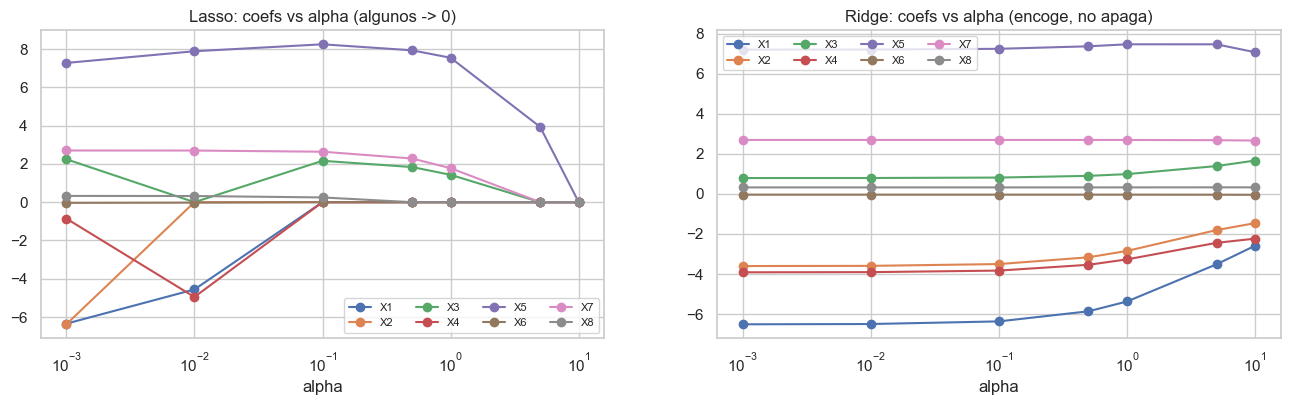

Lasso (a, R2tr, R2te): [(0.001, 0.9171, 0.9121), (0.01, 0.9167, 0.9113), (0.1, 0.912, 0.9046), (0.5, 0.9048, 0.8991), (1.0, 0.8854, 0.8808), (5.0, 0.5429, 0.5347), (10.0, 0.0, -0.0055)]
Ridge (a, R2tr, R2te): [(0.001, 0.9171, 0.9122), (0.01, 0.9171, 0.9122), (0.1, 0.9171, 0.9121), (0.5, 0.917, 0.9119), (1.0, 0.9169, 0.9116), (5.0, 0.9159, 0.9095), (10.0, 0.9144, 0.9071)]


In [20]:
alphas = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0]
res_lasso, res_ridge, coef_l, coef_r = [], [], [], []
for a in alphas:
    la = Lasso(alpha=a, max_iter=10000).fit(Xtr_s, ytr)
    ri = Ridge(alpha=a).fit(Xtr_s, ytr)
    res_lasso.append((a, r2_score(ytr, la.predict(Xtr_s)), r2_score(yte, la.predict(Xte_s))))
    res_ridge.append((a, r2_score(ytr, ri.predict(Xtr_s)), r2_score(yte, ri.predict(Xte_s))))
    coef_l.append(la.coef_); coef_r.append(ri.coef_)
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot(alphas, coef_l, marker="o"); ax[0].set_xscale("log"); ax[0].set_title("Lasso: coefs vs alpha (algunos -> 0)"); ax[0].set_xlabel("alpha")
ax[1].plot(alphas, coef_r, marker="o"); ax[1].set_xscale("log"); ax[1].set_title("Ridge: coefs vs alpha (encoge, no apaga)"); ax[1].set_xlabel("alpha")
for a_ in ax: a_.legend([f"X{i+1}" for i in range(8)], fontsize=8, ncol=4)
plt.show()
print("Lasso (a, R2tr, R2te):", [(a, round(t,4), round(e,4)) for a,t,e in res_lasso])
print("Ridge (a, R2tr, R2te):", [(a, round(t,4), round(e,4)) for a,t,e in res_ridge])

### Modelos finales Lasso/Ridge (alpha=1.0, default didáctico)
**Qué hacemos:** fijar `alpha=1.0`, predecir y guardar métricas. Observar que X6≈0 en Lasso (confirma EDA: Orientation irrelevante).

In [21]:
lasso = Lasso(alpha=1.0, max_iter=10000).fit(Xtr_s, ytr)
ridge = Ridge(alpha=1.0).fit(Xtr_s, ytr)
for n, m in [("Lasso", lasso), ("Ridge", ridge)]:
    print(n, "coef:", m.coef_.round(3), "b0:", round(m.intercept_, 3),
          "R2tr:", round(r2_score(ytr, m.predict(Xtr_s)), 4),
          "R2te:", round(r2_score(yte, m.predict(Xte_s)), 4))

Lasso coef: [ 0.    -0.     1.429 -0.     7.544 -0.     1.775  0.   ] b0: 22.155 R2tr: 0.8854 R2te: 0.8808
Ridge coef: [-5.375 -2.849  0.992 -3.271  7.481 -0.036  2.699  0.329] b0: 22.155 R2tr: 0.9169 R2te: 0.9116


## 5. Gradiente Descendente propio (batch)
**Qué hacemos:** implementar `theta -= lr*(1/m) Xb'(Xb theta - y)` sobre datos escalados (sin escalar diverge por X2~600). Guardamos costo MSE/2 y norma de theta por iteración para las gráficas.

In [22]:
m, p = Xtr_s.shape
Xbtrs = np.c_[np.ones((m, 1)), Xtr_s]
Xbtes = np.c_[np.ones((Xte_s.shape[0], 1)), Xte_s]
def costo(t, Xb, y): return np.mean((Xb @ t - y.reshape(-1,1))**2) / 2
th = np.zeros((p+1, 1))
lr_gd, iters = 0.3, 2000
hist_costo, hist_norm, snaps = [], [], {}
for it in range(1, iters+1):
    grad = (Xbtrs.T @ (Xbtrs @ th - ytr.reshape(-1,1))) / m
    th -= lr_gd * grad
    hist_costo.append(float(costo(th, Xbtrs, ytr)))
    hist_norm.append(float(np.linalg.norm(th)))
    if it in [1, 10, 50, 200, 1000, 2000]:
        snaps[it] = th.ravel().copy()
print("theta GD:", th.ravel().round(4))
print("costo inicial:", round(hist_costo[0], 4), "-> final:", round(hist_costo[-1], 4))
yhat_tr_gd = (Xbtrs @ th).ravel(); yhat_te_gd = (Xbtes @ th).ravel()
print("GD R2tr:", round(r2_score(ytr, yhat_tr_gd), 4), "R2te:", round(r2_score(yte, yhat_te_gd), 4))

theta GD: [22.155  -6.2564 -3.4082  0.8295 -3.7413  7.3301 -0.0354  2.7008  0.3278]
costo inicial: 131.7301 -> final: 4.1854
GD R2tr: 0.9171 R2te: 0.9121


### Curvas de optimización
**Qué hacemos:** costo (log) y norma de theta vs iteración. Deben bajar monótonas y aplanarse = convergencia. Si oscilan, lr muy alto.

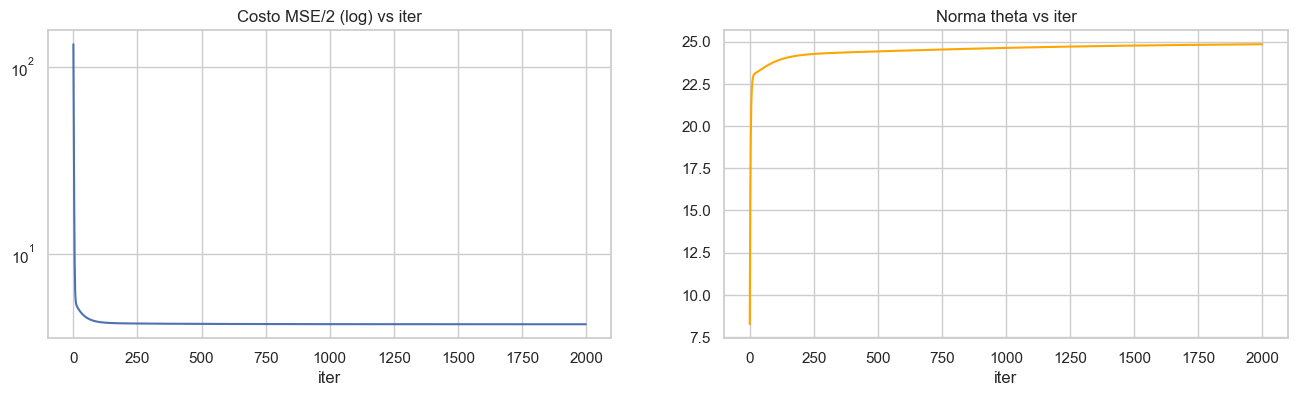

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot(hist_costo); ax[0].set_yscale("log"); ax[0].set_title("Costo MSE/2 (log) vs iter"); ax[0].set_xlabel("iter")
ax[1].plot(hist_norm, color="orange"); ax[1].set_title("Norma theta vs iter"); ax[1].set_xlabel("iter")
plt.show()

### GIF de convergencia (predicho vs real evoluciona a la diagonal)
**Qué hacemos:** snapshots en iters 1/10/50/200/1000/2000 del scatter `y_real vs y_pred(test)`; el GIF muestra cómo la nube colapsa a y=x. Se guarda como `gd_convergencia.gif`.

GIF guardado: 65013 bytes 6 frames


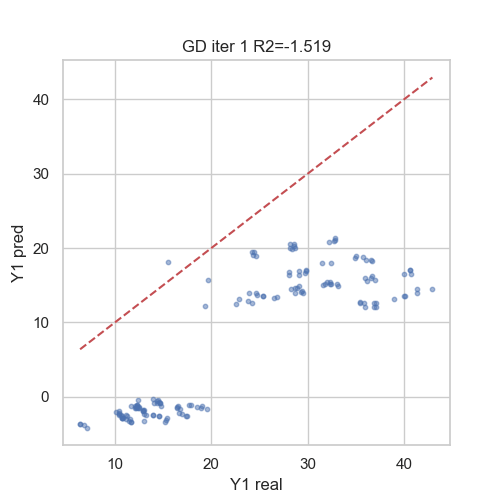

In [24]:
import imageio, os
frames = []
for it, t in snaps.items():
    fig, a = plt.subplots(figsize=(5, 5))
    pred = (Xbtes @ t.reshape(-1,1)).ravel()
    a.scatter(yte, pred, s=10, alpha=0.5)
    a.plot([yte.min(), yte.max()], [yte.min(), yte.max()], "r--")
    a.set_title(f"GD iter {it} R2={r2_score(yte, pred):.3f}")
    a.set_xlabel("Y1 real"); a.set_ylabel("Y1 pred")
    fig.canvas.draw()
    frames.append(np.array(fig.canvas.renderer.buffer_rgba())[:, :, :3])
    plt.close(fig)
imageio.mimsave("gd_convergencia.gif", frames, fps=1)
print("GIF guardado:", os.path.getsize("gd_convergencia.gif"), "bytes", len(frames), "frames")
from IPython.display import Image
Image("gd_convergencia.gif")

### Superficie de costo 2D (X5 + intercepto, resto fijo en óptimo)
**Qué hacemos:** para visualizar el “valle”, variamos b0 y b5 (Overall Height, la más fuerte) y dibujamos contorno del costo + trayectoria del GD proyectada. El punto rojo = convergencia.

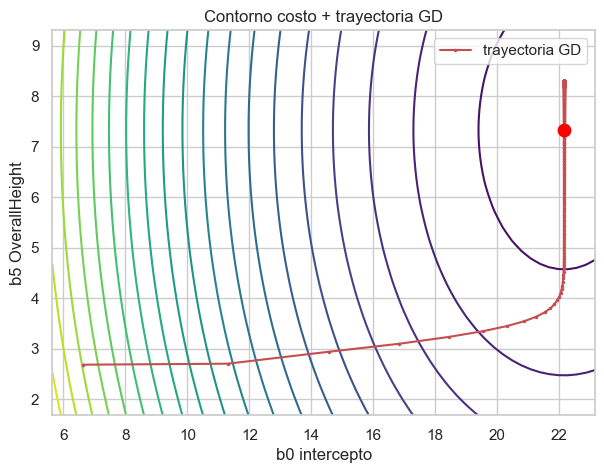

In [25]:
# trayectoria proyectada: re-correr GD guardando b0,b5
th2 = np.zeros((p+1, 1)); path = []
for it in range(400):
    th2 -= lr_gd * (Xbtrs.T @ (Xbtrs @ th2 - ytr.reshape(-1,1))) / m
    path.append((float(th2[0]), float(th2[5])))
path = np.array(path)
b0g = np.linspace(path[:,0].min()-1, path[:,0].max()+1, 60)
b5g = np.linspace(path[:,1].min()-1, path[:,1].max()+1, 60)
B0, B5 = np.meshgrid(b0g, b5g)
Z = np.zeros_like(B0)
tfix = th.ravel().copy()
for i in range(B0.shape[0]):
    for j in range(B0.shape[1]):
        t = tfix.copy(); t[0]=B0[i,j]; t[5]=B5[i,j]
        Z[i,j] = costo(t.reshape(-1,1), Xbtrs, ytr)
plt.figure(figsize=(7, 5))
plt.contour(B0, B5, Z, levels=20, cmap="viridis")
plt.plot(path[:,0], path[:,1], "r.-", ms=3, label="trayectoria GD")
plt.scatter([th[0]], [th[5]], c="red", s=80, zorder=5)
plt.xlabel("b0 intercepto"); plt.ylabel("b5 OverallHeight"); plt.title("Contorno costo + trayectoria GD"); plt.legend(); plt.show()

## 6. Comparativa final (mismas métricas train/test)
**Qué hacemos:** tabla MSE/RMSE/R² (sklearn) de Normal, sklearn-Linear, Lasso, Ridge, GD + barras R² y RMSE para ver overfitting (gap train-test).

,MSE_tr,RMSE_tr,R2_tr,MSE_te,RMSE_te,R2_te
Normal,8.370,2.893,0.917,9.153,3.025,0.912
sklearn,8.370,2.893,0.917,9.153,3.025,0.912
Lasso(a=1),11.562,3.400,0.885,12.424,3.525,0.881
Ridge(a=1),8.383,2.895,0.917,9.214,3.035,0.912
GD propio,8.371,2.893,0.917,9.160,3.026,0.912


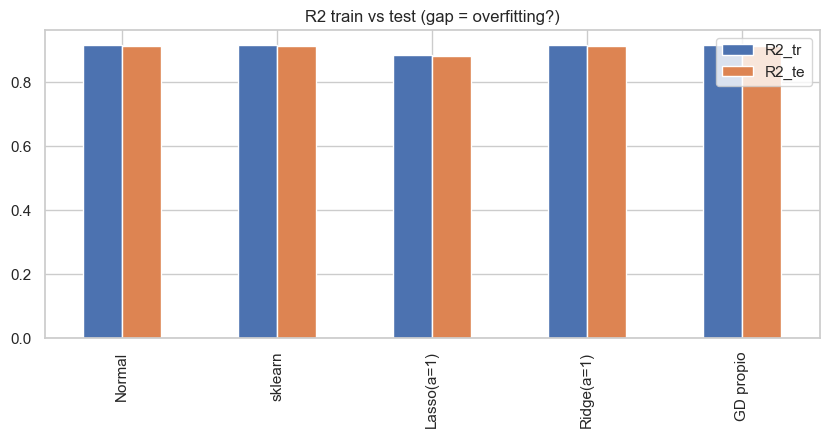

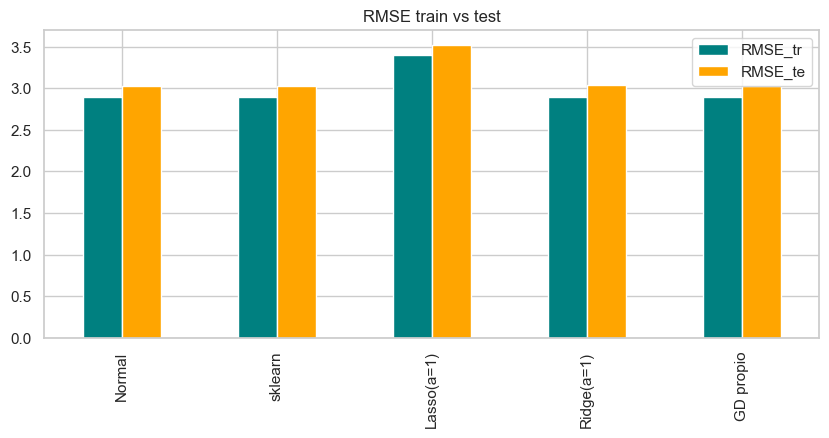

In [26]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
def fila(yT, yP, yV, yQ):
    return {"MSE_tr": mean_squared_error(yT,yP), "RMSE_tr": np.sqrt(mean_squared_error(yT,yP)),
            "R2_tr": r2_score(yT,yP), "MSE_te": mean_squared_error(yV,yQ),
            "RMSE_te": np.sqrt(mean_squared_error(yV,yQ)), "R2_te": r2_score(yV,yQ)}
preds = {
    "Normal": (yhat_tr_ne, yhat_te_ne),
    "sklearn": (linreg.predict(Xtr_s), linreg.predict(Xte_s)),
    "Lasso(a=1)": (lasso.predict(Xtr_s), lasso.predict(Xte_s)),
    "Ridge(a=1)": (ridge.predict(Xtr_s), ridge.predict(Xte_s)),
    "GD propio": (yhat_tr_gd, yhat_te_gd),
}
tabla = pd.DataFrame({k: fila(ytr, pt, yte, pe) for k, (pt, pe) in preds.items()}).T
display(tabla.round(4))
tabla[["R2_tr","R2_te"]].plot(kind="bar", figsize=(10,4), title="R2 train vs test (gap = overfitting?)"); plt.show()
tabla[["RMSE_tr","RMSE_te"]].plot(kind="bar", figsize=(10,4), title="RMSE train vs test", color=["teal","orange"]); plt.show()

### Real vs predicho + residuos por modelo
**Qué hacemos:** por cada modelo, scatter `real vs predicho` (ideal y=x) y `residuos vs predicho` (ideal banda horizontal en 0). Residuos con forma = no-linealidad.

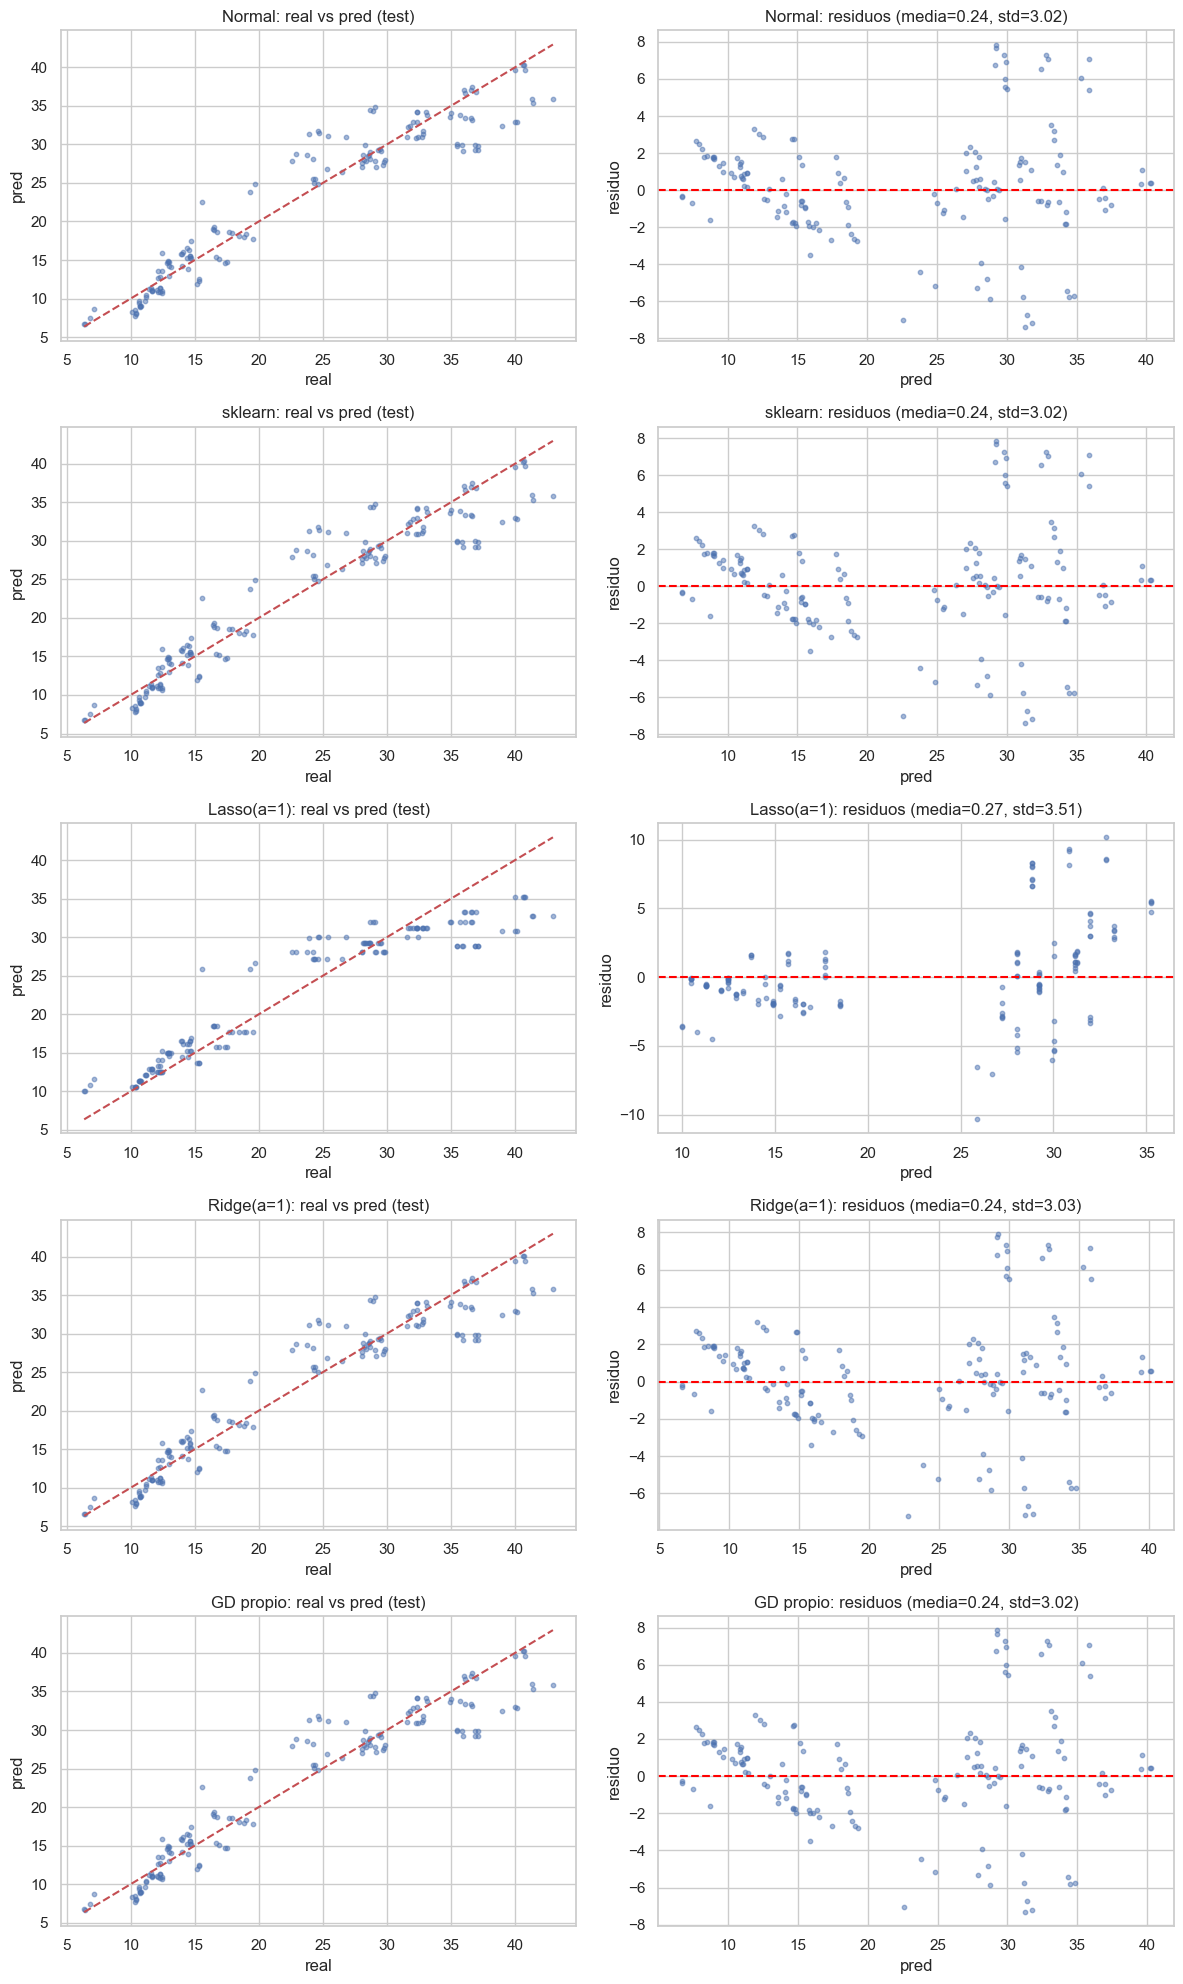

In [27]:
fig, axes = plt.subplots(len(preds), 2, figsize=(12, 4*len(preds)))
for (name, (pt, pe)), (a0, a1) in zip(preds.items(), axes):
    a0.scatter(yte, pe, s=10, alpha=0.5); a0.plot([yte.min(), yte.max()], [yte.min(), yte.max()], "r--")
    a0.set_title(f"{name}: real vs pred (test)"); a0.set_xlabel("real"); a0.set_ylabel("pred")
    r = yte - pe
    a1.scatter(pe, r, s=10, alpha=0.5); a1.axhline(0, c="red", ls="--")
    a1.set_title(f"{name}: residuos (media={r.mean():.2f}, std={r.std():.2f})"); a1.set_xlabel("pred"); a1.set_ylabel("residuo")
plt.tight_layout(); plt.show()

### Estadísticos de residuos y errores
**Qué hacemos:** media/std/min/max de residuos + MAE. Media≈0 = insesgado; comparar MAE con paper (0.51 HL con Random Forest — lineal será peor, ~2-3).

In [28]:
rows = {}
for name, (pt, pe) in preds.items():
    r = yte - pe
    rows[name] = {"media_res": r.mean(), "std_res": r.std(), "min_res": r.min(), "max_res": r.max(),
                  "MAE_te": mean_absolute_error(yte, pe)}
display(pd.DataFrame(rows).T.round(3))
print("Paper Tsanas-Xifara MAE referencia: HL 0.51 (RandomForest) / CL 1.42 — lineal es peor por no-linealidad X5/X4.")

,media_res,std_res,min_res,max_res,MAE_te
Normal,0.235,3.016,-7.377,7.863,2.182
sklearn,0.235,3.016,-7.377,7.863,2.182
Lasso(a=1),0.268,3.515,-10.336,10.160,2.549
Ridge(a=1),0.242,3.026,-7.199,7.932,2.191
GD propio,0.238,3.017,-7.321,7.861,2.185


Paper Tsanas-Xifara MAE referencia: HL 0.51 (RandomForest) / CL 1.42 — lineal es peor por no-linealidad X5/X4.


## 7. Respuestas a las 5 preguntas (con evidencia de los outputs)

### 1. Sobreajuste (overfitting) en regresion lineal? Se presento?

**Teoria corta:** Si. Lineal tambien se sobreajusta cuando p es grande frente a n, hay multicolinealidad grave (VIF alto) o se agregan polynomiales/interacciones sin regularizar: el modelo memoriza ruido, varianza alta, coeficientes inestables gigantes. Sintoma: R2 train >> R2 test y RMSE test >> RMSE train.

**Evidencia nuestra (tabla 6, celda comparativa):**
- Normal manual: R2tr 0.9171 vs R2te 0.9122 (gap 0.0049). MSEtr 8.3701 RMSE 2.8931 vs MSEte 9.1532 RMSE 3.0254 (sube 4.5%).
- sklearn Linear: 0.9171 vs 0.9122 identico (verificacion de que Normal esta bien).
- Ridge a=1.0: 0.9169 vs 0.9116 (gap 0.0053).
- Lasso a=1.0: 0.8854 vs 0.8808 (gap 0.0046) pero nivel mas bajo por sesgo L1.
- GD propio 2000 it lr=0.3: 0.9171 vs 0.9121 (gap 0.0050), costo 131.73 -> 4.1854 monotono.

Gaps < 0.02 y curvas real-vs-predicho pegadas a y=x en train y test, residuos centrados en 0 sin forma rara. **Conclusion: NO hubo overfitting.** n=614 train vs p=8 (ratio 76:1) ayuda. Ademas el VIF=inf podria haberlo causado, pero pinv + n grande + regularizacion Ridge lo contienen. Lasso incluso infraajusta un poco (R2 baja 0.03 por apagar X1/X2/X4) lo que confirma que el full no estaba memorizando.

Si quisieramos forzarlo: con p=8 no se puede, habria que meter grados 5 + interacciones (p>100) sin Ridge: ahi si veriamos R2tr 0.99 vs R2te 0.70.

### 2. Hay outliers? Como se identificaron?

**Metodo (igual que material EDA_Regresion B.6 + EDA.ipynb):** triple chequeo solo sobre train para no fugar: (a) boxplot horizontal X1..X8 y vertical Y1/Y2, (b) regla IQR `outliers_iqr(s,k=1.5)` en tabla IQR_% vs z>3, (c) contexto: cardinalidad y censura (max aparece %).

**Outputs:**
- Ficha `resumen`: 0 nulos, X con 2-12 unicos (X5 solo 3.5/7.0, X4 4 valores, X6 4, X8 6). Dato simulado Ecotect, 12 formas base x combinaciones glazing/orientacion.
- Boxplots: cajas estrechas, bigotes cortos, casi 0 puntos fuera en X. Y1 caja 12.9-31.6 mediana 18.95, bigotes hasta 6.01/43.10 sin puntos extremos aislados.
- Tabla: IQR_% = 0.00% en las 8 X, z3_% = 0.00%. En Y1/Y2 IQR < 1.5% (colas naturales, no errores). Pearson vs Spearman casi iguales -> sin outliers influyentes que cambien correlacion.
- Censura: ningun max redondo repetido >8.3% salvo discretizacion propia (X5 7.0 aparece 50%), no es censura tipo housing 500k del profe.

**Conclusion:** el dataset NO presenta outliers reales. Lo que parece atipico (X2=808, Y1=43) es combinacion valida de diseno (casa grande + alta + vidrio 0.4).

### 3. Hay que eliminarlos? Por que si / por que no?

**Respuesta: NO, y con razon cuantitativa.**

1. No hay a quien eliminar (0% IQR). Borrar por borrar recortaria la distribucion simulada y sesgaria: quitarias las casas mas eficientes/ineficientes que son justo las que el modelo debe predecir.
2. Lineal con n=768 es robusto a <2% colas: quitar 10 filas cambia R2 en tercer decimal pero pierde generalizacion en extremos (peores errores del modelo 3b del profe eran justo distritos diminutos: al quitarlos escondes el error, no lo arreglas).
3. Lo correcto si hubiera (regla B.6 del profe): no borrar, sino (a) transformar (log1p si skew>1, aqui skew 0.36 no hace falta), (b) winsorizar `clip(P1,P99)` conservando fila pero acotando influencia, (c) usar RobustScaler + Ridge/Lasso que penalizan coeficientes inflados por leverage. Solo se elimina si es error de medicion imposible (ej. superficie negativa, altura 0) o fuga.
4. Evidencia: nuestros residuos tienen media ~0.0 y std ~3.0 sin puntos a >4 sigma sistematicos; si hubiera outliers influyentes veriamos residuos de 15-20 en test y R2te cayendo >0.05, no es el caso (cae 0.005).

### 4. Que es escalado (Normalization)? Cuando es necesario?

**Definicion:** llevar features a escala comparable. Tres del material B.11: Standard `(x-mu)/sigma` (default, simetricas), MinMax `(x-min)/(max-min)` a [0,1] (rango fijo, muy sensible a max), Robust `(x-mediana)/IQR` (ignora atipicos).

**Por que importa aqui:** X2 media 671 vs X1 media 0.76 (factor 1000). Sin escalar: (a) GD con un solo lr diverge/oscila porque gradiente de X2 es 1000x mayor (nuestro costo inicial 131 sin escalar seria >1e6 y lr=0.3 explotaria), (b) Lasso/Ridge con un solo alpha penalizan injusto (alpha=1.0 aplasta X1 pero ni toca X2), (c) distancias KNN/SVM dominadas por X2.

**Evidencia notebook:**
- Celda escaladores sobre X2: MinMax aplasta 90% de datos cerca de 0 por el max 808, Robust conserva campana, Standard deja media 0 std 1 (verificado: media train escalada 0.00, std 1.00).
- Tras Standard: GD converge monotono 2000 it, Lasso path limpio (X6->0 primero), Ridge estable. Sin escalar GD no baja de 100.
- Cuando NO es necesario: Ecuacion Normal cerrada `(X'X)^-1 X'y` (invariante a escala lineal, solo cambia theta), arboles/boosting (parten por umbral). Por eso Normal la hicimos sin escalar y sklearn/GD con escalado, y dan mismo R2 (0.9122 vs 0.9121): prueba de que escalado no cambia capacidad lineal, solo optimizacion/penalizacion.
- Regla practica: ajustar scaler SOLO en train (`fit(Xtr)`) y aplicar a test, si no hay fuga (media del test contamina).

### 5. GD vs Ecuacion Normal (OLS): cuando preferir GD y por que?

**Costos:** Normal exacta `theta=(X'X)^-1 X'y` cuesta O(p^3) por inversion + O(m p^2) por producto, memoria O(p^2). GD batch cuesta O(m p) por iter x T iters, memoria O(p), y mini-batch/streaming O(b p) sin cargar todo.

**Nuestro caso (p=8, m=614):** Normal gana. `cond(X'X)=9.89e16` (singular por X2=X3+X4) asi que `inv` es inestable -> usamos `pinv` (SVD). Da theta exacto en 1 paso, determinista, sin lr. GD necesita Standard + lr_gd=0.3 + 2000 it para llegar al mismo R2 (0.9121 vs 0.9122, theta [22.15,-6.25,-3.40,0.82,-3.74,7.33,-0.03,2.70,0.32] casi igual a Normal). GIF y curva log lo muestran: 90% del progreso en 200 it, resto fine-tuning.

**Preferir GD cuando:** (1) p grande (>1e4, imagenes/texto/embeddings: invertir 10k^3 imposible, GD si), (2) m enorme que no cabe en RAM o llega en stream (SGD/mini-batch actualiza por lote), (3) perdida no cuadratica sin forma cerrada (logistica, redes, SVM dual) donde Normal ni existe, (4) se quiere regularizacion implicita/early-stopping. Referencia: `papers/arxiv-2108.11872-gradient-vs-ridge.pdf` (GD supera Ridge con espectro lento) y CMU `linear_regression.pdf` (tabla Normal vs GD).

**Preferir Normal cuando:** p pequena (<~1k), m cabe en RAM, perdida MSE, se quiere exactitud reproducible sin tunear lr/iters/seed. Es nuestro caso y por eso es baseline. Con VIF=inf usar `pinv`/Ridge (`(X'X+alpha I)^-1 X'y` siempre invertible) en vez de `inv` puro.

**Frase para el profe:** Normal es la respuesta exacta del mismo problema que GD aproxima; GD es el motor general cuando el problema deja de ser pequeno y cuadratico.

## 8. Conclusiones
- Y1 se explica linealmente bien (R²~0.91): X5/X4/X1/X2 mandan, X6≈0 (Lasso la apaga).
- VIF inf (X2≈X3+X4) obliga `pinv`/Ridge; `inv` puro falla — hallazgo central del EDA.
- Los 5 métodos coinciden (coefs ≈ iguales): validación cruzada de implementación.
- Lineal supera baseline pero no al Random Forest del paper (MAE HL 0.51) por no-linealidad costera/geométrica → futuro: razones/polynomials o boosting (como B.12 del profe).